In [1]:
# Cell 1: Setup, load the feature series, check plotting/statistics libraries
from pathlib import Path
import importlib
import polars as pl

PROJECT_DIR = Path.cwd().parent
FEAT = PROJECT_DIR / "data/processed/series_dev_features.parquet"
FIG_DIR = PROJECT_DIR / "reports/figures/eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

for lib in ["matplotlib", "numpy", "pandas", "statsmodels", "scipy"]:
    try:
        m = importlib.import_module(lib)
        print(f"{lib:12s} {getattr(m, '__version__', '?')}")
    except ImportError:
        print(f"{lib:12s} MISSING")

df = pl.read_parquet(FEAT).sort("minute_epoch")
print("\nrows:", df.height, "| columns:", len(df.columns))
print("range:", df["minute_local"].min(), "->", df["minute_local"].max())

# Valid minutes for analysis: not an outage, not on a maintenance day
valid = (~pl.col("outage")) & (~pl.col("maint_day"))
print(df.select(
    valid.sum().alias("valid_minutes"),
    pl.col("maint_day").sum().alias("maint_day_minutes"),
    pl.col("outage").sum().alias("outage_minutes"),
    (pl.col("power_W") == 0).sum().alias("zero_power_minutes"),
))
print(df.filter(valid).select(
    (pl.col("power_W").min() / 1000).alias("min_kW"),
    (pl.col("power_W").median() / 1000).alias("median_kW"),
    (pl.col("power_W").max() / 1000).alias("max_kW"),
))

matplotlib   3.11.2
numpy        2.4.6
pandas       3.0.6
statsmodels  0.15.0
scipy        1.17.1

rows: 10080 | columns: 20
range: 2021-09-10 00:00:00 -> 2021-09-16 23:59:00
shape: (1, 4)
┌───────────────┬───────────────────┬────────────────┬────────────────────┐
│ valid_minutes ┆ maint_day_minutes ┆ outage_minutes ┆ zero_power_minutes │
│ ---           ┆ ---               ┆ ---            ┆ ---                │
│ u32           ┆ u32               ┆ u32            ┆ u32                │
╞═══════════════╪═══════════════════╪════════════════╪════════════════════╡
│ 8640          ┆ 1440              ┆ 674            ┆ 48                 │
└───────────────┴───────────────────┴────────────────┴────────────────────┘
shape: (1, 3)
┌───────────┬───────────┬───────────┐
│ min_kW    ┆ median_kW ┆ max_kW    │
│ ---       ┆ ---       ┆ ---       │
│ f64       ┆ f64       ┆ f64       │
╞═══════════╪═══════════╪═══════════╡
│ 21.626367 ┆ 31.069278 ┆ 42.199823 │
└───────────┴───────────┴───────────┘

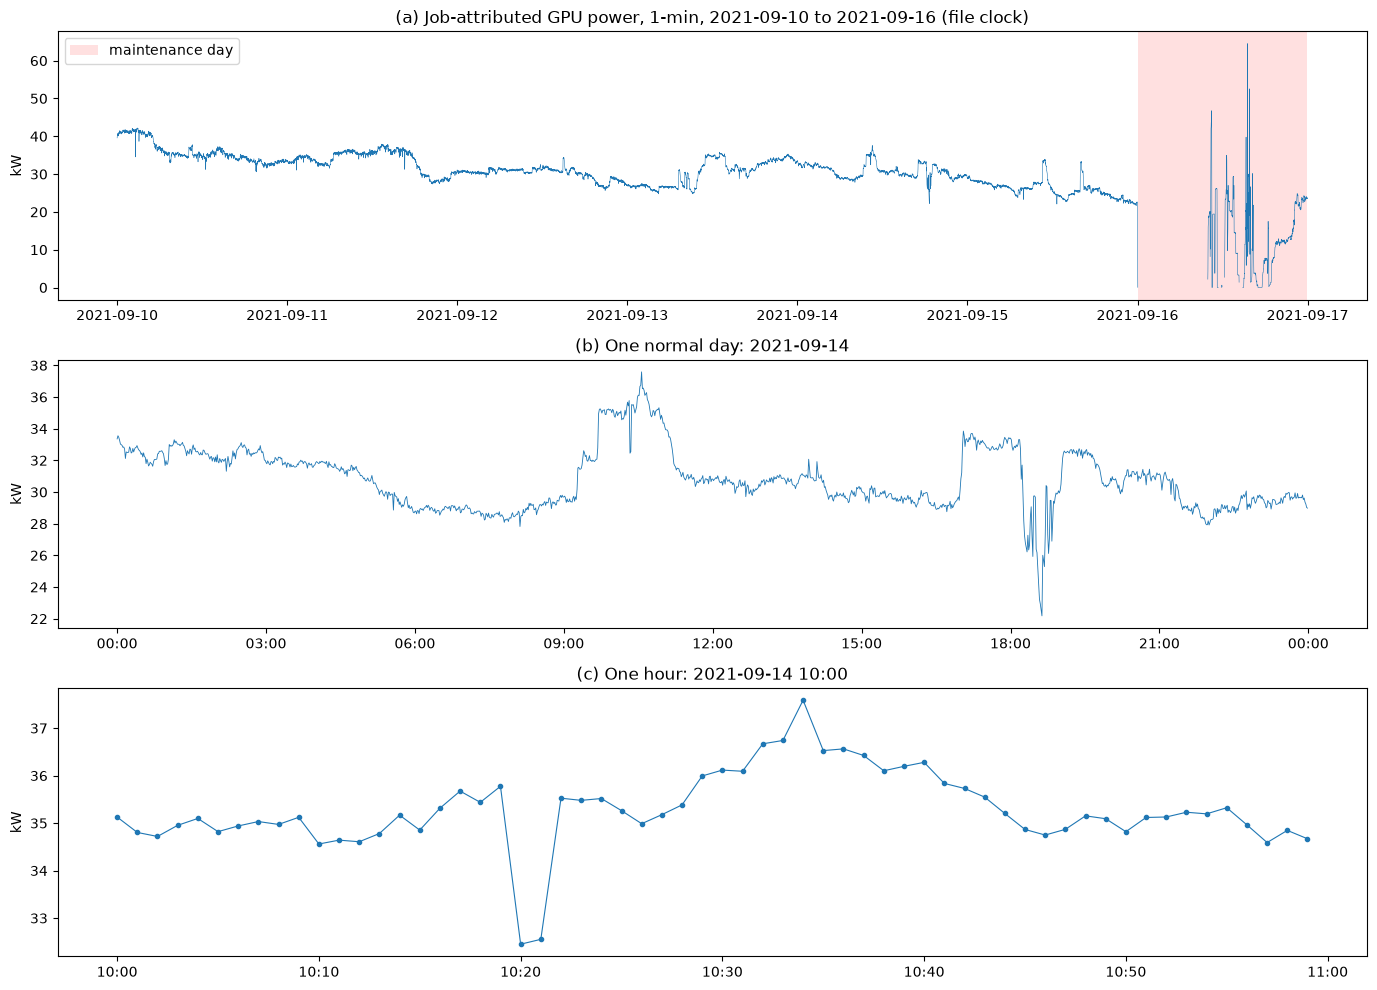

normal-day stats: mean 31.2 kW, std 4.0 kW
saved: /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/reports/figures/eda/01_series_week_day_hour.png


In [4]:
# Cell 2: Full week, one normal day, one hour (figures saved to reports/figures/eda/)
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

p = df.select("minute_local", (pl.col("power_W") / 1000).alias("kW"), "maint_day", "outage").to_pandas()

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# (a) Full window, maintenance day shaded
ax = axes[0]
ax.plot(p["minute_local"], p["kW"], lw=0.4)
md = p.loc[p["maint_day"], "minute_local"]
ax.axvspan(md.min(), md.max(), color="red", alpha=0.12, lw=0, label="maintenance day")
ax.set_title("(a) Job-attributed GPU power, 1-min, 2021-09-10 to 2021-09-16 (file clock)")
ax.set_ylabel("kW")
ax.legend(loc="upper left")

# (b) One normal day
day = p[(p["minute_local"] >= "2021-09-14") & (p["minute_local"] < "2021-09-15")]
axes[1].plot(day["minute_local"], day["kW"], lw=0.6)
axes[1].set_title("(b) One normal day: 2021-09-14")
axes[1].set_ylabel("kW")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

# (c) One hour around the highest power of that day
peak_t = day.loc[day["kW"].idxmax(), "minute_local"].floor("h")
hr = p[(p["minute_local"] >= peak_t) & (p["minute_local"] < peak_t + pd.Timedelta(hours=1))]
axes[2].plot(hr["minute_local"], hr["kW"], marker=".", lw=0.8)
axes[2].set_title(f"(c) One hour: {peak_t:%Y-%m-%d %H:00}")
axes[2].set_ylabel("kW")
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

plt.tight_layout()
fig.savefig(FIG_DIR / "01_series_week_day_hour.png", dpi=150)
plt.show()

normal = p.loc[~p["maint_day"], "kW"]
print(f"normal-day stats: mean {normal.mean():.1f} kW, std {normal.std():.1f} kW")
print("saved:", FIG_DIR / "01_series_week_day_hour.png")

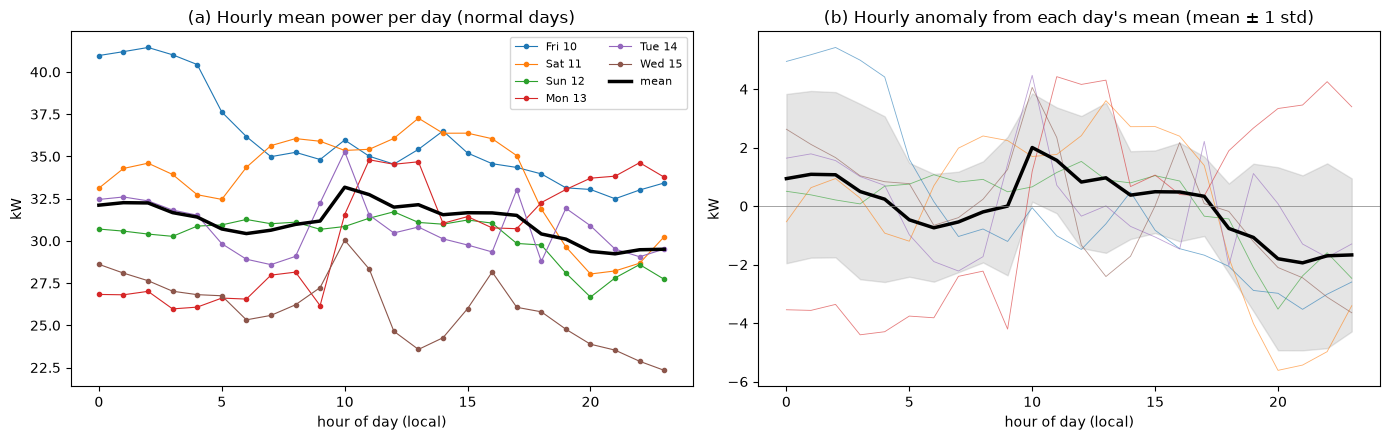

daily means (kW): [36.0, 33.7, 30.2, 30.4, 30.8, 26.0]
share of within-day hourly variance explained by hour-of-day: 0.20
saved: /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/reports/figures/eda/02_daily_profile.png


In [5]:
# Cell 3: Daily profile on normal days (hour-of-day means per day, plus the mean over days)
import numpy as np

nd = (df.filter(~pl.col("maint_day"))
        .with_columns(pl.col("minute_local").dt.date().alias("date"),
                      pl.col("minute_local").dt.hour().alias("hour"),
                      (pl.col("power_W") / 1000).alias("kW")))

hourly = nd.group_by("date", "hour").agg(pl.col("kW").mean()).sort("date", "hour")
prof = hourly.group_by("hour").agg(pl.col("kW").mean().alias("mean"), pl.col("kW").std().alias("std")).sort("hour")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for d in hourly["date"].unique().sort():
    h = hourly.filter(pl.col("date") == d)
    axes[0].plot(h["hour"], h["kW"], marker=".", lw=0.8, label=f"{d:%a %d}")
axes[0].plot(prof["hour"], prof["mean"], color="black", lw=2.5, label="mean")
axes[0].set_title("(a) Hourly mean power per day (normal days)")
axes[0].set_xlabel("hour of day (local)"); axes[0].set_ylabel("kW"); axes[0].legend(fontsize=8, ncol=2)

# Same, but each day minus its own daily mean (removes the multi-day trend)
hd = hourly.with_columns((pl.col("kW") - pl.col("kW").mean().over("date")).alias("anom"))
pa = hd.group_by("hour").agg(pl.col("anom").mean().alias("mean"), pl.col("anom").std().alias("std")).sort("hour")
for d in hd["date"].unique().sort():
    h = hd.filter(pl.col("date") == d)
    axes[1].plot(h["hour"], h["anom"], lw=0.6, alpha=0.6)
axes[1].plot(pa["hour"], pa["mean"], color="black", lw=2.5)
axes[1].fill_between(pa["hour"], pa["mean"] - pa["std"], pa["mean"] + pa["std"], color="gray", alpha=0.2)
axes[1].axhline(0, color="gray", lw=0.5)
axes[1].set_title("(b) Hourly anomaly from each day's mean (mean ± 1 std)")
axes[1].set_xlabel("hour of day (local)"); axes[1].set_ylabel("kW")

plt.tight_layout()
fig.savefig(FIG_DIR / "02_daily_profile.png", dpi=150)
plt.show()

# How much of the hourly variance is explained by hour-of-day (after removing daily means)?
ss_tot = ((hd["anom"]) ** 2).sum()
hd2 = hd.join(pa.select("hour", pl.col("mean").alias("hmean")), on="hour")
ss_res = ((hd2["anom"] - hd2["hmean"]) ** 2).sum()
print(f"daily means (kW): {[round(x, 1) for x in hourly.group_by('date').agg(pl.col('kW').mean()).sort('date')['kW']]}")
print(f"share of within-day hourly variance explained by hour-of-day: {1 - ss_res / ss_tot:.2f}")
print("saved:", FIG_DIR / "02_daily_profile.png")

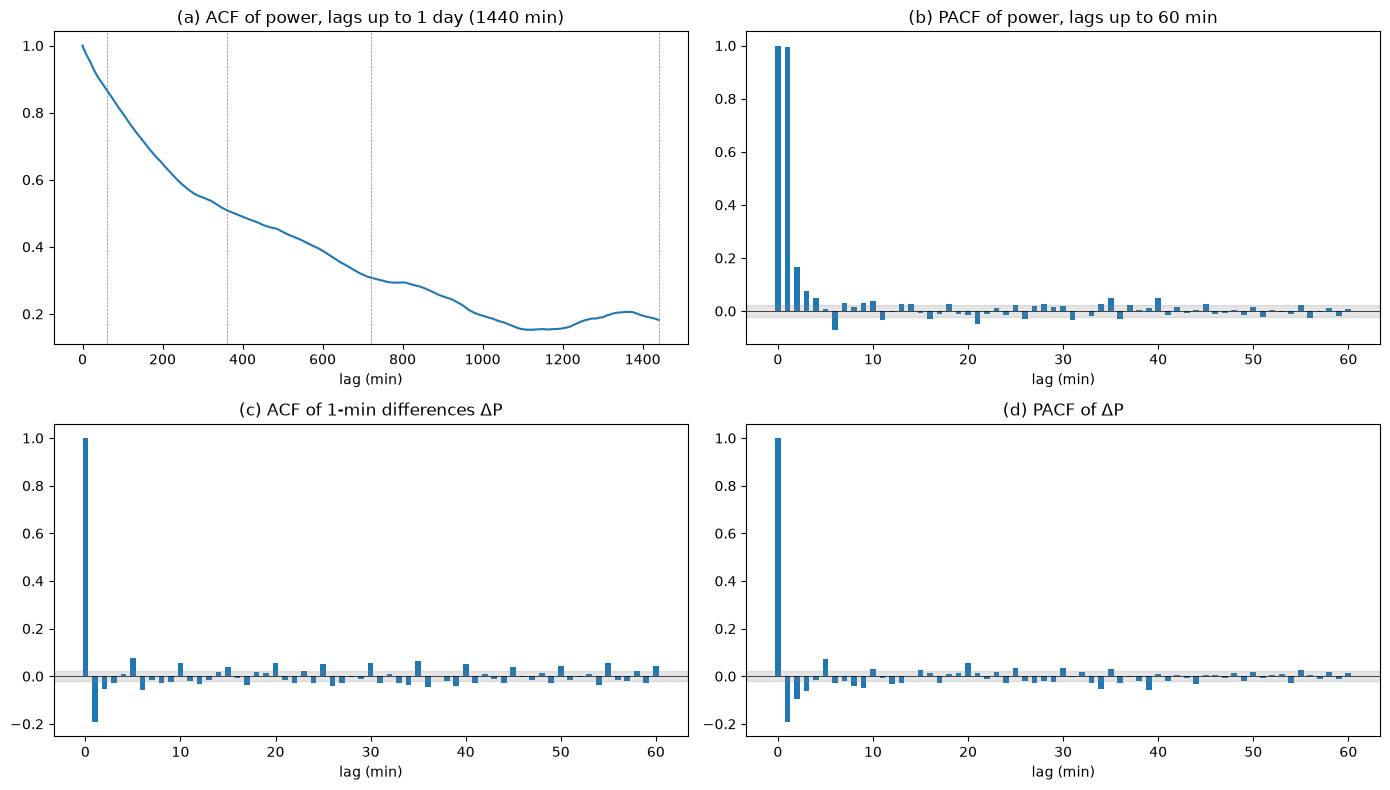

ACF(P) at lag 1, 5, 15, 60, 360, 1440: [np.float64(0.995), np.float64(0.985), np.float64(0.961), np.float64(0.869), np.float64(0.509), np.float64(0.182)]
first lag where ACF(P) < 0.5: 379 min
ACF(ΔP) at lag 1, 2, 3, 5: [np.float64(-0.193), np.float64(-0.054), np.float64(-0.028), np.float64(0.078)] | 95% band ±0.021
PACF(P) at lag 1, 2, 3: [np.float64(0.995), np.float64(0.166), np.float64(0.076)]
saved: /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/reports/figures/eda/03_acf_pacf.png


In [6]:
# Cell 4: ACF and PACF of power and of 1-min differences (normal days, contiguous 8,640 minutes)
from statsmodels.tsa.stattools import acf, pacf

x = df.filter(~pl.col("maint_day")).sort("minute_epoch")
assert x["minute_epoch"].diff().drop_nulls().unique().to_list() == [60], "normal-day minutes are not contiguous"
P = (x["power_W"] / 1000).to_numpy()
dP = np.diff(P)

ac_P = acf(P, nlags=1440, fft=True)
ac_dP = acf(dP, nlags=60, fft=True)
pac_P = pacf(P, nlags=60, method="ywm")
pac_dP = pacf(dP, nlags=60, method="ywm")
ci = 1.96 / np.sqrt(len(P))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].plot(ac_P); axes[0, 0].set_title("(a) ACF of power, lags up to 1 day (1440 min)")
for lag in (60, 360, 720, 1440):
    axes[0, 0].axvline(lag, color="gray", lw=0.5, ls="--")
axes[0, 1].bar(range(61), pac_P, width=0.6); axes[0, 1].set_title("(b) PACF of power, lags up to 60 min")
axes[1, 0].bar(range(61), ac_dP, width=0.6); axes[1, 0].set_title("(c) ACF of 1-min differences ΔP")
axes[1, 1].bar(range(61), pac_dP, width=0.6); axes[1, 1].set_title("(d) PACF of ΔP")
for ax in (axes[0, 1], axes[1, 0], axes[1, 1]):
    ax.axhspan(-ci, ci, color="gray", alpha=0.2); ax.axhline(0, color="black", lw=0.5)
for ax in axes.flat:
    ax.set_xlabel("lag (min)")
plt.tight_layout()
fig.savefig(FIG_DIR / "03_acf_pacf.png", dpi=150)
plt.show()

print(f"ACF(P) at lag 1, 5, 15, 60, 360, 1440: "
      f"{[round(ac_P[k], 3) for k in (1, 5, 15, 60, 360, 1440)]}")
print(f"first lag where ACF(P) < 0.5: {int(np.argmax(ac_P < 0.5)) if (ac_P < 0.5).any() else '> 1440'} min")
print(f"ACF(ΔP) at lag 1, 2, 3, 5: {[round(ac_dP[k], 3) for k in (1, 2, 3, 5)]} | 95% band ±{ci:.3f}")
print(f"PACF(P) at lag 1, 2, 3: {[round(pac_P[k], 3) for k in (1, 2, 3)]}")
print("saved:", FIG_DIR / "03_acf_pacf.png")

split (normal days only, chronological): train 6048, val 1296, test 1296 minutes
train ends 2021-09-14 04:47:00, val ends 2021-09-15 02:23:00
shape: (3, 11)
┌───────┬────────┬─────────┬─────────┬─────────────────────┬─────────┬─────────┬─────────────────┬──────────────────────┬──────────────┬───────────────┐
│ h_min ┆ std_kW ┆ p50_abs ┆ p90_abs ┆ p95_abs = threshold ┆ p99_abs ┆ max_abs ┆ excess_kurtosis ┆ share_up_among_ramps ┆ ramps_in_val ┆ ramps_in_test │
│ ---   ┆ ---    ┆ ---     ┆ ---     ┆ ---                 ┆ ---     ┆ ---     ┆ ---             ┆ ---                  ┆ ---          ┆ ---           │
│ i64   ┆ f64    ┆ f64     ┆ f64     ┆ f64                 ┆ f64     ┆ f64     ┆ f64             ┆ f64                  ┆ i64          ┆ i64           │
╞═══════╪════════╪═════════╪═════════╪═════════════════════╪═════════╪═════════╪═════════════════╪══════════════════════╪══════════════╪═══════════════╡
│ 1     ┆ 0.357  ┆ 0.166   ┆ 0.470   ┆ 0.618               ┆ 1.133   ┆ 7.105  

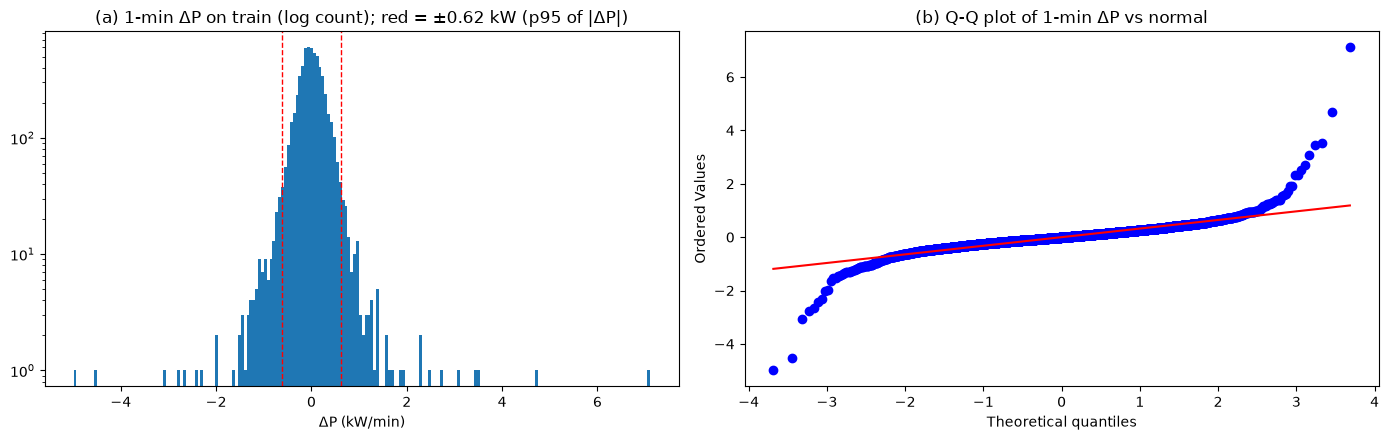


PROVISIONAL ramp threshold (h = 1 min): |ΔP| > 0.618 kW/min (1.9% of train median power)
saved: /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/reports/figures/eda/04_dP_distribution_ramp_threshold.png


In [7]:
# Cell 5: Distribution of ΔP, ramp statistics, PROVISIONAL ramp threshold (train = first 70%)
from scipy import stats

n = len(P)
n_tr, n_va = int(0.70 * n), int(0.15 * n)
print(f"split (normal days only, chronological): train {n_tr}, val {n_va}, test {n - n_tr - n_va} minutes")
print(f"train ends {x['minute_local'][n_tr - 1]}, val ends {x['minute_local'][n_tr + n_va - 1]}")

rows = []
for h in (1, 5, 15):
    d = P[h:] - P[:-h]                      # d[i] = P[i+h] - P[i]
    d_tr = d[: n_tr - h]                    # both endpoints inside train
    thr = np.percentile(np.abs(d_tr), 95)
    rows.append({
        "h_min": h,
        "std_kW": d_tr.std(),
        "p50_abs": np.percentile(np.abs(d_tr), 50),
        "p90_abs": np.percentile(np.abs(d_tr), 90),
        "p95_abs = threshold": thr,
        "p99_abs": np.percentile(np.abs(d_tr), 99),
        "max_abs": np.abs(d_tr).max(),
        "excess_kurtosis": stats.kurtosis(d_tr),
        "share_up_among_ramps": (d_tr[np.abs(d_tr) > thr] > 0).mean(),
        "ramps_in_val": int((np.abs(d[n_tr: n_tr + n_va - h]) > thr).sum()),
        "ramps_in_test": int((np.abs(d[n_tr + n_va:]) > thr).sum()),
    })
ramp_tab = pl.DataFrame(rows)
with pl.Config(tbl_cols=-1, float_precision=3, tbl_width_chars=200):
    print(ramp_tab)

# Figure: distribution of 1-min ΔP on train, log y-axis, with threshold
d1 = (P[1:] - P[:-1])[: n_tr - 1]
thr1 = rows[0]["p95_abs = threshold"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(d1, bins=200, color="tab:blue")
axes[0].set_yscale("log")
for s in (-thr1, thr1):
    axes[0].axvline(s, color="red", ls="--", lw=1)
axes[0].set_title(f"(a) 1-min ΔP on train (log count); red = ±{thr1:.2f} kW (p95 of |ΔP|)")
axes[0].set_xlabel("ΔP (kW/min)")

# Q-Q plot against a normal distribution: shows the heavy tails
stats.probplot(d1, dist="norm", plot=axes[1])
axes[1].set_title("(b) Q-Q plot of 1-min ΔP vs normal")
plt.tight_layout()
fig.savefig(FIG_DIR / "04_dP_distribution_ramp_threshold.png", dpi=150)
plt.show()

print(f"\nPROVISIONAL ramp threshold (h = 1 min): |ΔP| > {thr1:.3f} kW/min "
      f"({100 * thr1 / np.median(P[:n_tr]):.1f}% of train median power)")
print("saved:", FIG_DIR / "04_dP_distribution_ramp_threshold.png")

In [8]:
# Cell 6: Do covariates at time t predict future power changes P(t+h) - P(t)? (train only)
cov = ["active_gpu_jobs", "gpus_alloc", "queued_gpu_jobs", "queued_jobs", "n_gpu_equiv", "util_gpu_mean"]
X = x.select(cov).to_numpy().astype(float)
dX = np.vstack([np.full((1, X.shape[1]), np.nan), np.diff(X, axis=0)])   # change over the last minute

res = []
for h in (1, 5, 15):
    target = np.full(n, np.nan)
    target[: n - h] = P[h:] - P[: n - h]                                  # future change
    m = np.arange(n) < n_tr - h                                            # train only, target inside train
    for j, c in enumerate(cov):
        ok = m & ~np.isnan(target) & ~np.isnan(X[:, j]) & ~np.isnan(dX[:, j])
        res.append({"h_min": h, "covariate": c,
                    "corr_level": np.corrcoef(X[ok, j], target[ok])[0, 1],
                    "corr_change": np.corrcoef(dX[ok, j], target[ok])[0, 1]})
    ok = m & ~np.isnan(target)
    lastdP = np.concatenate([[np.nan], np.diff(P)])
    ok2 = ok & ~np.isnan(lastdP)
    res.append({"h_min": h, "covariate": "(own last ΔP)", "corr_level": np.nan,
                "corr_change": np.corrcoef(lastdP[ok2], target[ok2])[0, 1]})

lag_tab = pl.DataFrame(res).pivot(on="h_min", index="covariate", values=["corr_level", "corr_change"])
with pl.Config(tbl_cols=-1, float_precision=3, tbl_width_chars=200):
    print(lag_tab)
print(f"approx. 95% band for a correlation with n ≈ {n_tr}: ±{1.96 / np.sqrt(n_tr):.3f}")

shape: (7, 7)
┌─────────────────┬──────────────┬──────────────┬───────────────┬───────────────┬───────────────┬────────────────┐
│ covariate       ┆ corr_level_1 ┆ corr_level_5 ┆ corr_level_15 ┆ corr_change_1 ┆ corr_change_5 ┆ corr_change_15 │
│ ---             ┆ ---          ┆ ---          ┆ ---           ┆ ---           ┆ ---           ┆ ---            │
│ str             ┆ f64          ┆ f64          ┆ f64           ┆ f64           ┆ f64           ┆ f64            │
╞═════════════════╪══════════════╪══════════════╪═══════════════╪═══════════════╪═══════════════╪════════════════╡
│ active_gpu_jobs ┆ 0.001        ┆ -0.033       ┆ -0.084        ┆ 0.238         ┆ 0.214         ┆ 0.106          │
│ gpus_alloc      ┆ 0.002        ┆ -0.047       ┆ -0.113        ┆ 0.252         ┆ 0.215         ┆ 0.089          │
│ queued_gpu_jobs ┆ 0.014        ┆ 0.037        ┆ 0.060         ┆ 0.054         ┆ 0.037         ┆ 0.058          │
│ queued_jobs     ┆ 0.009        ┆ 0.027        ┆ 0.055         ┆ 

normal days, same minute:
shape: (1, 3)
┌─────────────────────────┬───────────────────────────┬──────────────────────────┐
│ corr(util, total power) ┆ corr(util, power per GPU) ┆ corr(n_gpu, total power) │
│ ---                     ┆ ---                       ┆ ---                      │
│ f64                     ┆ f64                       ┆ f64                      │
╞═════════════════════════╪═══════════════════════════╪══════════════════════════╡
│ 0.022778                ┆ 0.576335                  ┆ 0.883909                 │
└─────────────────────────┴───────────────────────────┴──────────────────────────┘

same-minute changes:
shape: (1, 2)
┌───────────────────────────┬──────────────────────────┐
│ corr(Δutil, Δn_gpu_equiv) ┆ corr(Δutil, Δgpus_alloc) │
│ ---                       ┆ ---                      │
│ f64                       ┆ f64                      │
╞═══════════════════════════╪══════════════════════════╡
│ -0.216949                 ┆ -0.13551                 │
└

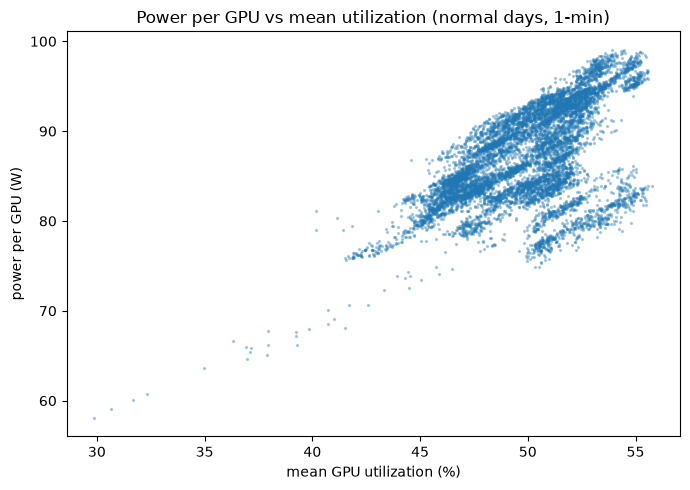

saved: /Users/aryaneuse/Desktop/Other/datacenter-power-forecasting/reports/figures/eda/05_power_per_gpu_vs_util.png


In [9]:
# Cell 7: Power per GPU vs utilization, and the composition effect behind the negative Δutil correlation
v = x.filter(pl.col("n_gpu_equiv") > 0).with_columns(
    (pl.col("power_W") / pl.col("n_gpu_equiv")).alias("W_per_gpu"))

print("normal days, same minute:")
print(v.select(
    pl.corr("util_gpu_mean", "power_W").alias("corr(util, total power)"),
    pl.corr("util_gpu_mean", "W_per_gpu").alias("corr(util, power per GPU)"),
    pl.corr("n_gpu_equiv", "power_W").alias("corr(n_gpu, total power)"),
))

# Composition test: is a drop in mean utilization accompanied by more GPUs?
c = x.select(pl.col("util_gpu_mean").diff().alias("d_util"),
             pl.col("n_gpu_equiv").diff().alias("d_ngpu"),
             pl.col("gpus_alloc").diff().alias("d_alloc")).drop_nulls()
print("\nsame-minute changes:")
print(c.select(pl.corr("d_util", "d_ngpu").alias("corr(Δutil, Δn_gpu_equiv)"),
               pl.corr("d_util", "d_alloc").alias("corr(Δutil, Δgpus_alloc)")))

# Mean utilization change in minutes where GPUs were added vs removed vs unchanged
print(c.with_columns(pl.when(pl.col("d_alloc") > 0).then(pl.lit("GPUs added"))
                       .when(pl.col("d_alloc") < 0).then(pl.lit("GPUs removed"))
                       .otherwise(pl.lit("no change")).alias("event"))
       .group_by("event").agg(pl.len().alias("minutes"), pl.col("d_util").mean().alias("mean Δutil (pp)"))
       .sort("event"))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(v["util_gpu_mean"], v["W_per_gpu"], s=2, alpha=0.3)
ax.set_xlabel("mean GPU utilization (%)"); ax.set_ylabel("power per GPU (W)")
ax.set_title("Power per GPU vs mean utilization (normal days, 1-min)")
plt.tight_layout()
fig.savefig(FIG_DIR / "05_power_per_gpu_vs_util.png", dpi=150)
plt.show()
print("saved:", FIG_DIR / "05_power_per_gpu_vs_util.png")

## Summary of findings (development window, normal days 2021-09-10 to 2021-09-15)

All statistics use the 8,640 contiguous normal-day minutes; the maintenance day (2021-09-16) is excluded.
One week is short: every finding below is provisional until a longer series is built.

1. **Level and trend.** Mean 31.2 kW, std 4.0 kW, range 21.6 to 42.2 kW. Daily means fall from
   36.0 to 26.0 kW over six days, so the test split sits at a lower level than the training split.
2. **No reliable daily cycle.** Hour of day explains 0.20 of within-day hourly variance, close to
   the about 0.16 expected from fitting 24 means to pure noise (rough estimate). No visible weekend effect (one weekend only).
3. **Step-like load.** Power moves in steps of a few kW when large jobs start or end, with small
   minute-scale noise (about ±0.5 kW) and occasional two-minute dips that revert.
4. **Strong persistence.** ACF of power: 0.995 (1 min), 0.985 (5 min), 0.961 (15 min), 0.869 (60 min);
   below 0.5 only after 379 min. PACF is negligible beyond lag 2 to 3, so a 60-minute input window
   covers the short-term linear dynamics. Persistence will be a hard baseline.
5. **Mean reversion in changes.** ACF of 1-min ΔP at lag 1 is -0.19 (95% band ±0.02); later lags are small.
6. **Heavy-tailed ramps.** Excess kurtosis of 1-min ΔP is 50; median |ΔP| 0.17 kW, max 7.1 kW/min.
   Ramps are symmetric (about 50% up).
7. **Provisional ramp thresholds** (95th percentile of |P(t+h) - P(t)| on the first 70% of normal days):
   **0.618 kW (h = 1)**, 1.005 kW (h = 5), 1.684 kW (h = 15). The 99th percentiles are 1.13, 2.18 and
   3.28 kW. Because the 1-min threshold is close to normal minute-scale noise, a second, severe-ramp
   tier at the 99th percentile is proposed for discussion.
8. **Covariates.** Same-minute correlation with power: active GPU jobs 0.89, allocated GPUs 0.88,
   queued GPU jobs 0.28. For future changes, covariate *changes* matter, not levels:
   Δ allocated GPUs +0.25 (h = 1) and +0.22 (h = 5); Δ mean utilization -0.35 (h = 1);
   queues at most 0.06. Partly mechanical (allocation is seen at minute end, power fully only in the
   next minute). Joint value to be tested by ablation.
9. **Structure.** Total power ≈ number of active GPUs × power per GPU. Utilization correlates with
   power per GPU (0.58) but not with total power (0.02). Power per GPU is 58 to 98 W, far below the
   V100 maximum. A two-part (count × intensity) model is a possible physics-informed design.

Figures: `reports/figures/eda/01` to `05`.